<a href="https://colab.research.google.com/github/nmhom/MAT-422/blob/main/MAT422_HW4_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# HW 4.1 & 4.2 - Network Analysis and Graph Modeling

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

np.set_printoptions(precision = 3, suppress = True)



## 4.1

A lot of data comes as a network: people on social media, connections between websites, or correlations between variables. Networks are modeled as graphs. Each individual is a node, and an edge connects two nodes that are related.

Networks often have **communities**: groups of nodes that are more connected to each other than to the rest of the graph. Finding them helps with things like friend recommendations. This chapter uses spectral clustering, which finds communities using the eigenvalues and eigenvectors of matrices built from the graph.

## 4.2 Graph Modeling

A graph $G(V,E)$ has a set of nodes $V$ and a set of edges $E$.

- **Undirected graph:** edges go both ways (like Facebook friends)
- **Directed graph:** edges have a direction (like Twitter followers)
- **Degree** of a node: the number of edges connected to it.
- **Adjacency matrix** $A$: $A_{ij} = 1$ if nodes $i$ and $j$ are connected, and 0 if not. For an undirected graph, $A$ is symmetric.

### Example 4.2.1: Eigenvector Centrality

Take the 3-node graph $v_1 - v_2 - v_3$. Its adjacency matrix is

$$A = \begin{pmatrix} 0 & 1 & 0 \\ 1 & 0 & 1 \\ 0 & 1 & 0 \end{pmatrix}$$

To measure how important each node is, we solve $Ac = \lambda c$ and use the eigenvector $c$ for the largest eigenvalue. The book gets eigenvalues $-\sqrt{2}, 0, \sqrt{2}$ and $c = \left(\tfrac{1}{2}, \tfrac{\sqrt{2}}{2}, \tfrac{1}{2}\right)$.

In [2]:
A = np.array([[0,1,0], [1,0,1], [0,1,0]])

print("Degrees:", A.sum(axis=1)) # row sums = degree of each node
vals, vecs = np.linalg.eig(A)
print("Eigenvalues:", vals)

c = np.abs(vecs[:, -1])
print("Centrality:", c)
print("Book answer:", np.array([1/2, np.sqrt(2)/2, 1/2]))

Degrees: [1 2 1]
Eigenvalues: [-1.414  0.     1.414]
Centrality: [0.5   0.707 0.5  ]
Book answer: [0.5   0.707 0.5  ]


This matches the book. Node $v_2$ has the highest centrality because it sits in the middle and connects to both other nodes. Nodes $v_1$ and $v_3$ are tied.

(I used `np.abs` because NumPy can return the eigenvector with all its signs flipped, which is still a valid eigenvector.)

### Example 4.2.2: The Laplacian Matrix

For a weighted graph, the Laplacian is $$L = D - M$$

where $M$ is the adjacency matrix (with weights) and $D$ is the diagonal matrix of degrees, $D_{ii} = \sum_k E_{ik}$.

The book uses a star graph: node 1 is connected to nodes 2, 3 and 4 with weights $e_1, e_2, e_3$. I used $e_1 = 1$, $e_2 = 2$, $e_3 = 3$.

The incidence matrix $I_G$ has one row per node and one column per edge. For edge $\{i, j\}$, the column has $\sqrt{E_{ij}}$ in row $i$, $-\sqrt{E_{i}}$ in row $j$, and 0 everywhere else.

In [3]:
e1, e2, e3 = 1,2,3

# adjacency matrix with weights
M = np.array([[0, e1, e2, e3],
              [e1, 0, 0, 0],
              [e2, 0, 0, 0],
              [e3, 0, 0, 0]])
D = np.diag(M.sum(axis = 1)) # degree matrix
L = D - M # laplacian
print("L = \n", L)

# incidence matrix: one column per edge
IG = np.array([[ np.sqrt(e1), np.sqrt(e2), np.sqrt(e3)],
               [-np.sqrt(e1), 0, 0],
               [0, -np.sqrt(e2), 0],
               [0, 0, -np.sqrt(e3)]])

L = 
 [[ 6 -1 -2 -3]
 [-1  1  0  0]
 [-2  0  2  0]
 [-3  0  0  3]]


### Theorem 4.2.3: Properties of the Laplacian

The next cell checks the properties from the theroem on this example:

1. $L = D - M$ (used above to build $L$)
2. $L = I_G I_G^T$
3. $L$ is symmetric and all its eigenvalues are $\ge 0$ (positive semidefinite)
4. $Le = 0$ for $e = (1, \dots, 1)^T$, so 0 is the smallest eigenvalue
5. $x^T L x = \sum_{(i,j) \in E} E_{ij}(x_i - x_j)^2$

In [4]:
print("L == IG IG^T:", np.allclose(L, IG @ IG.T))
print("Symmetric:", np.allclose(L, L.T))
print("Eigenvalues:", np.linalg.eigvalsh(L))

e = np.ones(4)
print("L e =", L @ e)

x = np.array([1,2,3,4])
print("x^T L x =", x @ L @ x)
print("Sum of E_ij (x_i - x_j)^2 =", e1*(x[0]-x[1])**2 + e2*(x[0]-x[2])**2 + e3*(x[0]-x[3])**2)

L == IG IG^T: True
Symmetric: True
Eigenvalues: [0.    1.194 2.387 8.419]
L e = [0. 0. 0. 0.]
x^T L x = 36
Sum of E_ij (x_i - x_j)^2 = 36


All the properties hold. The eigenvalues are all $\ge 0$, the smallest one is exactly 0, and $Le = 0$.

The formula $x^T L x = \sum E_{ij}(x_i - x_j)^2$ is important. It is small when connected nodes have similar values of $x$, which is the idea behind using $L$ to find communities.

### Property 5: Connected Components

If a graph has $c$ separate pieces (connected components), then $L$ has exactly $c$ eigenvalues equal to 0.

To test this, I made a graph with 2 pieces: $v_1 - v_2 - v_3$ and $v_4 - v_4$.

In [5]:
M2 = np.array([[0, 1, 0, 0, 0],
               [1, 0, 1, 0, 0],
               [0, 1, 0, 0, 0],
               [0, 0, 0, 0, 1],
               [0, 0, 0, 1, 0]])

L2 = np.diag(M2.sum(axis=1)) - M2
print("Eigenvalues:", np.linalg.eigvalsh(L2))

Eigenvalues: [0. 0. 1. 2. 3.]


There are two zero eigenvalues, one for each piece of the graph.

### Corollary 4.2.5 and the Fiedler Vector

The Courant-Fischer theorem says that for a symmetric matrix with eigenvalues $\lambda_1 \le \lambda_2 \le |dots$, $$\min_{x \ne 0,\ x^T v_1 = 0} \frac{x^T A x}{x^T x} = \lambda_2$$

For the Laplacian, $v_1$ is the all-ones vector $e$. So the smallest value of $\frac{x^T L x}{x^T x}$ over all $x$ with $x^T e = 0$ is $\lambda_2$, and it happens at the eigenvector for $\lambda_2$. This eigenvector is called the Fiedler vector.

Since $x^T L x$ is small when connected nodes have similar values, the Fiedler vector gives similar values to nodes in the same group. Splitting the nodes by the sign of the Fiedler vector splits the graph into two communities.

To test this, I made a graph with two triangles (nodes 0, 1, 2 and nodes 3, 4, 5) joined by one edge between nodes 2 and 3.

Eigenvalues: [0.    0.438 3.    3.    3.    4.562]
Fiedler vector: [-0.465 -0.465 -0.261  0.261  0.465  0.465]
Rayleigh quotient at Fiedler vector: 0.4384471871911698
Smallest from random x: 0.6545349771861253


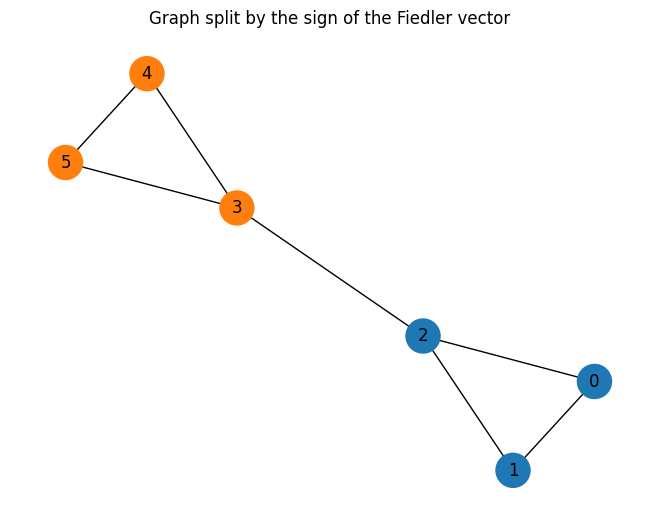

In [7]:
edges = [(0,1), (0,2), (1,2), # first triangle
         (3,4), (3,5), (4, 5), # second triangle
         (2,3),] # one edge joining them

M3 = np.zeros((6, 6))
for i,j in edges:
  M3[i, j] = M3[j, i] = 1

L3 = np.diag(M3.sum(axis=1)) - M3
vals, vecs = np.linalg.eigh(L3)
print("Eigenvalues:", vals)

f = vecs[:, 1] # fiedler vector (second smallest eigenvalue)
print("Fiedler vector:", f)

# x^T L x / x^T x at the Fiedler vector should equal lambda_2
print("Rayleigh quotient at Fiedler vector:", f @ L3 @ f / (f @ f))

# try 1000 random x with x^T e = 0; none should go below lambda_2
rng = np.random.default_rng(0)
smallest=np.inf

for _ in range(1000):
  x = rng.normal(size=6)
  x = x - x.mean()
  smallest = min(smallest, x @ L3 @ x / (x @ x))
print("Smallest from random x:", smallest)

# color nodes by the sign of the fiedler vector
G = nx.from_numpy_array(M3)
colors=["tab:blue" if v < 0 else "tab:orange" for v in f]
nx.draw(G, with_labels=True, node_color=colors, node_size=600)
plt.title("Graph split by the sign of the Fiedler vector")
plt.show()

The Rayleigh quotient at the Fiedler vector equals $\lambda_2 \approx 0.438$, and no random $x$ with $x^T e = 0$ got below it. This matches Corollary 4.2.5.

The Fiedler vector is negative on nodes 0, 1, 2 and positive on nodes 3, 4, 5, so the sign split finds the two triangles. This is the main idea behind spectral clustering.